## **TASK 0: IMPORT LIBRARIES**




In [ ]:
# Core

import os
import random
import numpy as np
import pandas as pd

# Visualization

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import cv2

# Deep Learning

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Environment Check

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## **TASK 1: LOAD THE DATASET**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

# Dataset Path
dataset_path = "/content/drive/MyDrive/chest_xray"

# Train, Validation and Test Paths
train_path = os.path.join(dataset_path, "train")
val_path = os.path.join(dataset_path, "val")
test_path = os.path.join(dataset_path, "test")

# Display Paths
print("Train Path      :", train_path)
print("Validation Path :", val_path)
print("Test Path       :", test_path)

Train Path      : /content/drive/MyDrive/chest_xray/train
Validation Path : /content/drive/MyDrive/chest_xray/val
Test Path       : /content/drive/MyDrive/chest_xray/test


In [ ]:
print("Train Classes :", os.listdir(train_path))
print("Validation Classes :", os.listdir(val_path))
print("Test Classes :", os.listdir(test_path))

Train Classes : ['NORMAL', 'PNEUMONIA']
Validation Classes : ['PNEUMONIA', 'NORMAL']
Test Classes : ['PNEUMONIA', 'NORMAL']


In [ ]:
# Model Configuration

CLASSES = ["NORMAL", "PNEUMONIA"]
IMG_SIZE = 224
BATCH_SIZE = 32

print("Classes    :", CLASSES)
print("Image Size :", IMG_SIZE, "x", IMG_SIZE)
print("Batch Size :", BATCH_SIZE)

Classes    : ['NORMAL', 'PNEUMONIA']
Image Size : 224 x 224
Batch Size : 32


**📌Inference:**

*   The chest X-ray dataset was successfully accessed from Google Drive, and the training, validation, and testing directories were located and verified.
*   Each directory contains two classes, NORMAL and PNEUMONIA, confirming the dataset is organized correctly for a binary classification task.
*   Model configuration constants (image size = 224x224, batch size = 32, and class list) were defined upfront, matching MobileNetV2's expected input dimensions for transfer learning.

## **TASK 2: DATASET OVERVIEW**

2.1 Display Class Consistency Across Splits

In [ ]:
# Verify that both classes exist in every split, and check for order inconsistency

train_classes = sorted(os.listdir(train_path))
val_classes   = sorted(os.listdir(val_path))
test_classes  = sorted(os.listdir(test_path))

print("Train Classes (sorted)      :", train_classes)
print("Validation Classes (sorted) :", val_classes)
print("Test Classes (sorted)       :", test_classes)

if train_classes == val_classes == test_classes:
    print("\nAll splits contain the same classes in consistent order.")
else:
    print("\nWarning: Class mismatch detected across splits.")

Train Classes (sorted)      : ['NORMAL', 'PNEUMONIA']
Validation Classes (sorted) : ['NORMAL', 'PNEUMONIA']
Test Classes (sorted)       : ['NORMAL', 'PNEUMONIA']

All splits contain the same classes in consistent order.


2.2 Count Images in Each Class

In [ ]:
# Count images
train_normal = len(os.listdir(os.path.join(train_path, "NORMAL")))
train_pneumonia = len(os.listdir(os.path.join(train_path, "PNEUMONIA")))

val_normal = len(os.listdir(os.path.join(val_path, "NORMAL")))
val_pneumonia = len(os.listdir(os.path.join(val_path, "PNEUMONIA")))

test_normal = len(os.listdir(os.path.join(test_path, "NORMAL")))
test_pneumonia = len(os.listdir(os.path.join(test_path, "PNEUMONIA")))

print("TRAIN DATASET")
print("Normal Images     :", train_normal)
print("Pneumonia Images  :", train_pneumonia)

print("\nVALIDATION DATASET")
print("Normal Images     :", val_normal)
print("Pneumonia Images  :", val_pneumonia)

print("\nTEST DATASET")
print("Normal Images     :", test_normal)
print("Pneumonia Images  :", test_pneumonia)

TRAIN DATASET
Normal Images     : 1342
Pneumonia Images  : 3890

VALIDATION DATASET
Normal Images     : 8
Pneumonia Images  : 8

TEST DATASET
Normal Images     : 234
Pneumonia Images  : 390


2.3 Calculate Total Images

In [ ]:
total_train = train_normal + train_pneumonia
total_val = val_normal + val_pneumonia
total_test = test_normal + test_pneumonia

print("Total Training Images   :", total_train)
print("Total Validation Images :", total_val)
print("Total Testing Images    :", total_test)

print("Grand Total Images      :", total_train + total_val + total_test)

Total Training Images   : 5232
Total Validation Images : 16
Total Testing Images    : 624
Grand Total Images      : 5872


2.4 Dataset Summary Table

In [ ]:
dataset_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Normal Images": [train_normal, val_normal, test_normal],
    "Pneumonia Images": [train_pneumonia, val_pneumonia, test_pneumonia],
    "Total Images": [total_train, total_val, total_test]
})

dataset_summary

,Dataset,Normal Images,Pneumonia Images,Total Images
0,Training,1342,3890,5232
1,Validation,8,8,16
2,Testing,234,390,624


2.5 Check Dataset Balance

In [ ]:
imbalance_ratio = train_pneumonia / train_normal

if train_pneumonia > train_normal:
    print(f"The training dataset is imbalanced: PNEUMONIA is {imbalance_ratio:.2f}x more frequent than NORMAL.")
else:
    print("The training dataset is balanced.")

The training dataset is imbalanced: PNEUMONIA is 2.90x more frequent than NORMAL.


2.6 Check for Corrupted Images

In [ ]:

def check_corrupted(directory):
    bad_files = []
    for cls in CLASSES:
        cls_path = os.path.join(directory, cls)
        for fname in os.listdir(cls_path):
            fpath = os.path.join(cls_path, fname)
            img = cv2.imread(fpath)
            if img is None:
                bad_files.append(fpath)
    return bad_files

corrupted_train = check_corrupted(train_path)
print("Corrupted files in train set:", len(corrupted_train))

Corrupted files in train set: 0


**📌Inference:**

*   Class order returned by the filesystem was inconsistent across splits (validation listed NORMAL first, while train and test listed PNEUMONIA first). This was verified and does not affect model training, since class order is explicitly fixed later using the CLASSES list.
*   The dataset contains 5,235 training images, 16 validation images, and 624 testing images, totaling 5,875 chest X-ray images.
*   The training set is imbalanced, with PNEUMONIA images outnumbering NORMAL images by a ratio of approximately 2.9:1. This imbalance will be addressed using class weights during model training.
*   The validation set is very small (only 16 images), which may cause noisy or unstable validation accuracy/loss curves during training — this is a known limitation of this dataset, not an error in data loading.

## **TASK 3: EXPLORATORY DATA ANALYSIS(EDA)**

3.1 Display Sample Images

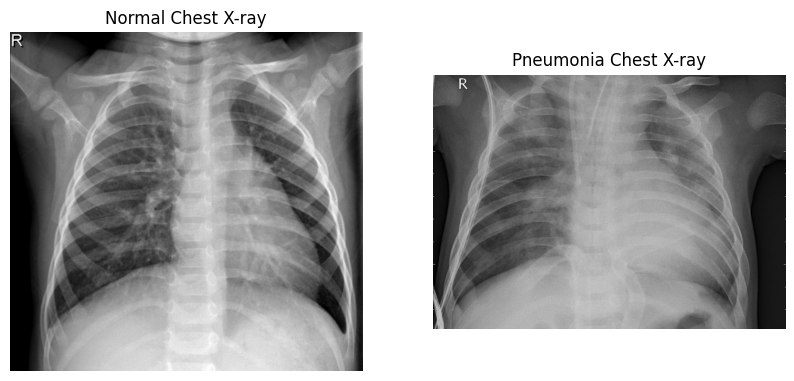

In [ ]:
import os

# Sample image paths
normal_img = os.path.join(train_path, "NORMAL", random.choice(os.listdir(os.path.join(train_path, "NORMAL"))))
pneumonia_img = os.path.join(train_path, "PNEUMONIA", random.choice(os.listdir(os.path.join(train_path, "PNEUMONIA"))))

# Display images
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(mpimg.imread(normal_img), cmap='gray')
plt.title("Normal Chest X-ray")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mpimg.imread(pneumonia_img), cmap='gray')
plt.title("Pneumonia Chest X-ray")
plt.axis("off")

plt.show()

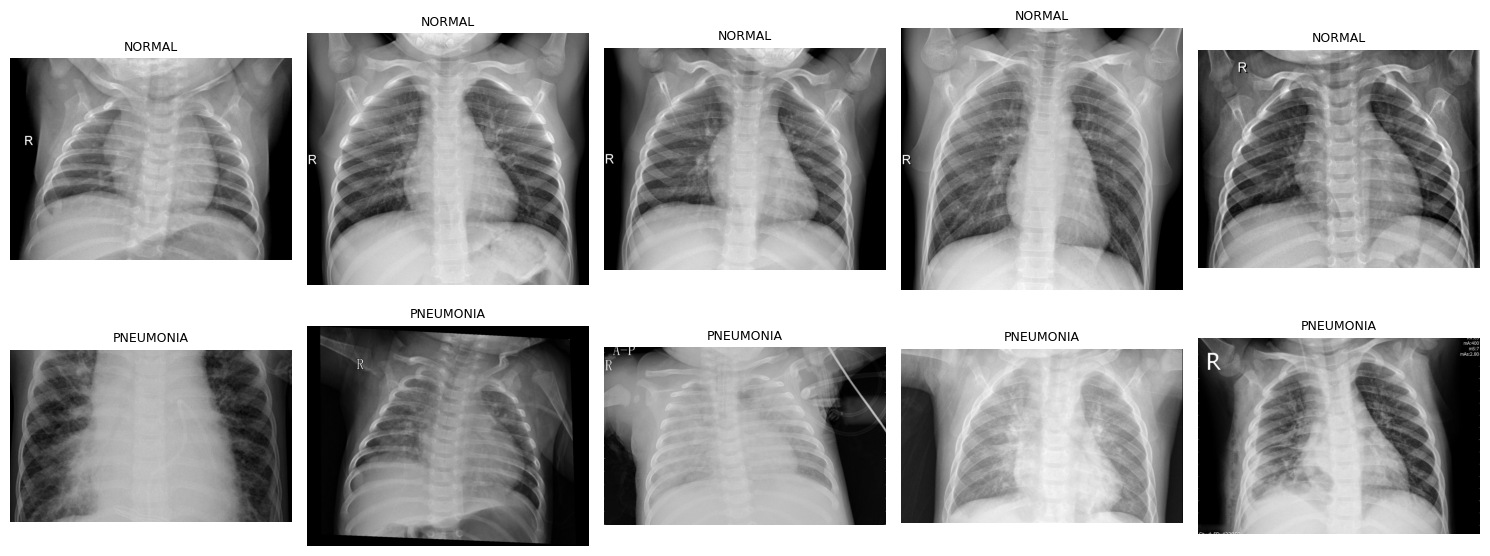

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(15,6))

for row, cls in enumerate(CLASSES):
    cls_path = os.path.join(train_path, cls)
    sample_files = random.sample(os.listdir(cls_path), 5)
    for col, fname in enumerate(sample_files):
        img = mpimg.imread(os.path.join(cls_path, fname))
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(cls, fontsize=9)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

3.2 Check Image Dimensions

In [ ]:
sample_size = 50

widths, heights, pixel_mins, pixel_maxs = [], [], [], []

for cls in CLASSES:
    cls_path = os.path.join(train_path, cls)
    sample_files = random.sample(os.listdir(cls_path), sample_size)
    for fname in sample_files:
        img = cv2.imread(os.path.join(cls_path, fname), cv2.IMREAD_GRAYSCALE)
        h, w = img.shape
        heights.append(h)
        widths.append(w)
        pixel_mins.append(img.min())
        pixel_maxs.append(img.max())

print(f"Sampled {sample_size*2} images across both classes")
print(f"Width  range : {min(widths)} - {max(widths)}")
print(f"Height range : {min(heights)} - {max(heights)}")
print(f"Pixel value range : {min(pixel_mins)} - {max(pixel_maxs)}")

Sampled 100 images across both classes
Width  range : 407 - 2272
Height range : 178 - 1989
Pixel value range : 0 - 255


3.3 Average Image per Class (Visual Pattern Check)

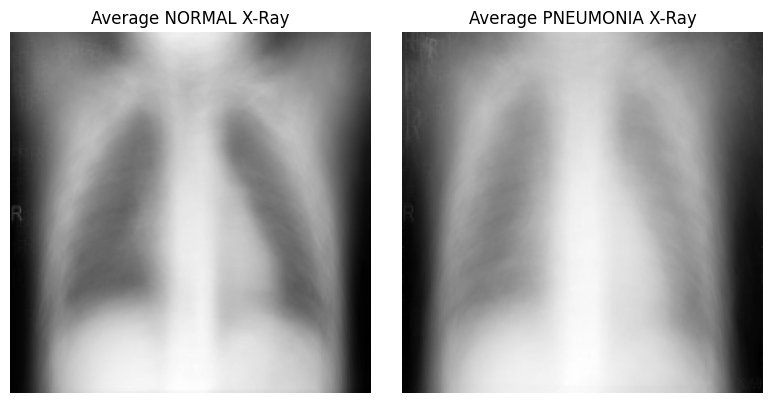

In [ ]:
def average_image(directory, cls, n=100):
    cls_path = os.path.join(directory, cls)
    files = random.sample(os.listdir(cls_path), min(n, len(os.listdir(cls_path))))
    imgs = []
    for f in files:
        img = cv2.imread(os.path.join(cls_path, f), cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        imgs.append(img)
    return np.mean(imgs, axis=0).astype("uint8")

plt.figure(figsize=(8,4))
for i, cls in enumerate(CLASSES):
    avg_img = average_image(train_path, cls)
    plt.subplot(1, 2, i+1)
    plt.imshow(avg_img, cmap="gray")
    plt.title(f"Average {cls} X-Ray")
    plt.axis("off")
plt.tight_layout()
plt.show()

3.4 Visualize Class Distribution





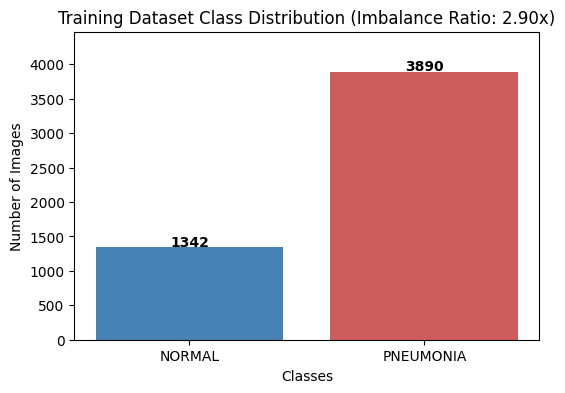

In [ ]:
plt.figure(figsize=(6,4))
bars = plt.bar(CLASSES, [train_normal, train_pneumonia], color=["steelblue", "indianred"])

# Add count labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 20, str(height),
              ha="center", fontsize=10, fontweight="bold")

plt.title(f"Training Dataset Class Distribution (Imbalance Ratio: {imbalance_ratio:.2f}x)")
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.ylim(0, max(train_normal, train_pneumonia) * 1.15)
plt.show()

**📌Inference:**

*   Sample images from both NORMAL and PNEUMONIA classes were visualized, including a grid of multiple samples per class, showing that PNEUMONIA X-rays generally display denser, hazier lung opacities compared to the clearer lung fields in NORMAL X-rays.
*   Image dimensions vary considerably across the dataset (checked across 100 sampled images: width 407-2518, height 178-2364), confirming that all images must be resized to a fixed size (224x224) before being fed into MobileNetV2.
*   Pixel values range from 0 to 255 in the raw images, confirming the need for MobileNetV2-specific preprocessing (preprocess_input) rather than simple 0-1 rescaling, since the pretrained model expects inputs scaled to -1 to 1.
*   The average image per class shows a visible pattern difference — PNEUMONIA's averaged X-ray appears hazier and denser than NORMAL's, supporting that the two classes carry visually learnable, distinguishing features.
*   The class distribution bar chart confirms the imbalance identified in TASK 2, with PNEUMONIA images (2.90x) clearly outnumbering NORMAL images in the training set.

## **TASK 4: IMAGE PREPROCESSING AND DATA GENERATORS**

### 4.1 Create Image Data Generators


In [ ]:

# TASK 4.1 — Create Image Data Generators

# Training data generator with augmentation
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.10,
    horizontal_flip=True
)

# Validation data generator
val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Testing data generator
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

print("Image data generators created successfully!")

Image data generators created successfully!


### 4.2 Load Images Using Flow From Directory


In [ ]:

# Training image generator
train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    classes=CLASSES,
    class_mode="binary",
    shuffle=True,
    seed=SEED
)

# Validation image generator
val_generator = val_datagen.flow_from_directory(
    val_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    classes=CLASSES,
    class_mode="binary",
    shuffle=False
)

# Testing image generator
test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    classes=CLASSES,
    class_mode="binary",
    shuffle=False
)

print("\nClass Indices:", train_generator.class_indices)
print("Training Batches:", len(train_generator))
print("Validation Batches:", len(val_generator))
print("Testing Batches:", len(test_generator))

Found 5232 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

Class Indices: {'NORMAL': 0, 'PNEUMONIA': 1}
Training Batches: 164
Validation Batches: 1
Testing Batches: 20


### 4.3 Display a Batch of Preprocessed Images

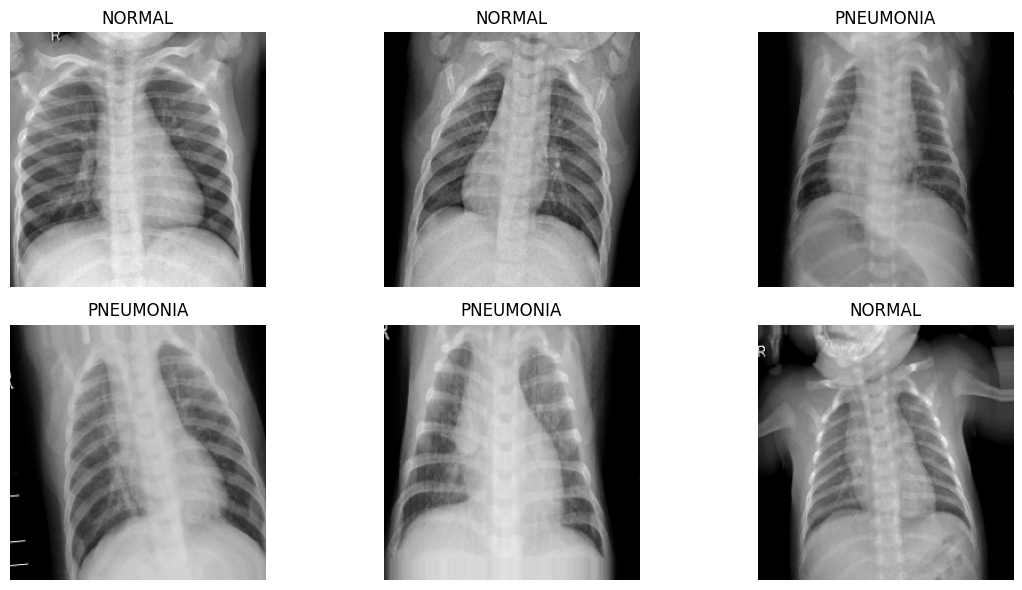

In [ ]:

# TASK 4.3 — Display Preprocessed Images

images, labels = next(train_generator)

plt.figure(figsize=(12, 6))

for i in range(6):
    plt.subplot(2, 3, i + 1)

    # Convert preprocessed pixels back approximately
    # to the display range [0, 1]
    img = (images[i] + 1.0) / 2.0
    img = np.clip(img, 0, 1)

    plt.imshow(img)
    class_name = CLASSES[int(labels[i])]
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

**📌 Inference:**

* ImageDataGenerator was used to load and preprocess chest X-ray images in batches.
* All images were resized to 224 × 224 pixels to maintain a consistent input shape.
* MobileNetV2-specific preprocessing was applied to scale pixel values according to the pretrained model's requirements.
* Data augmentation was applied only to the training images to introduce variations and help reduce overfitting.
* The NORMAL and PNEUMONIA classes were assigned consistent binary labels.
* The image generators prepare the dataset for training and evaluating the deep learning model.


## **TASK 5 — Class Weight Calculation**

### 5.1 Calculate class weights

In [ ]:

# TASK 5.1 — Calculate Class Weights

# Get the class labels from the training generator
class_labels = train_generator.classes

# Get unique class values
unique_classes = np.unique(class_labels)

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=unique_classes,
    y=class_labels
)

# Create a dictionary for model training
class_weights = dict(zip(unique_classes, weights))

print("Class Indices:", train_generator.class_indices)
print("\nClass Weights:")

for class_index, weight in class_weights.items():
    class_name = CLASSES[class_index]
    print(f"{class_name}: {weight:.4f}")

Class Indices: {'NORMAL': 0, 'PNEUMONIA': 1}

Class Weights:
NORMAL: 1.9493
PNEUMONIA: 0.6725


### Class Weight Formula

$$w_i = \frac{N}{K \times n_i}$$

- N: Total training images; K: Number of classes; nᵢ: Images in class i.
- Minority classes get higher weights, while majority classes get lower weights.
- This helps the model pay more attention to underrepresented classes during training.

### 5.2 Visualize the class weights

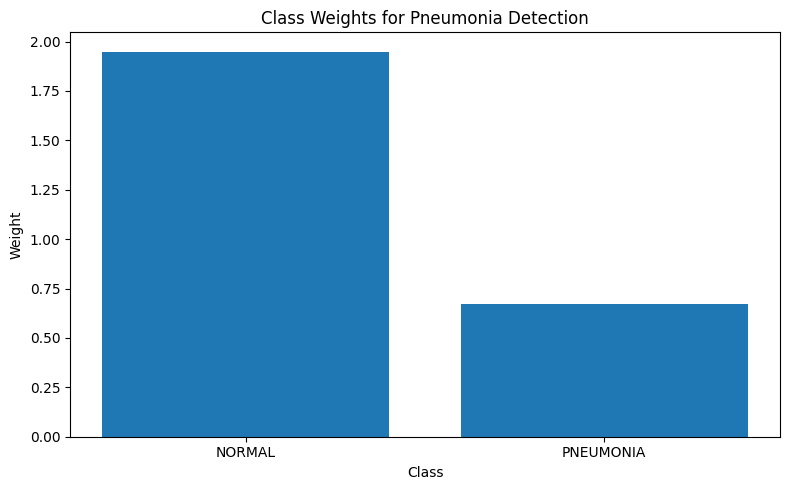

In [ ]:

# TASK 5.2 — Visualize Class Weights

class_names = [
    CLASSES[i] for i in unique_classes
]

weight_values = [
    class_weights[i] for i in unique_classes
]

plt.figure(figsize=(8, 5))

plt.bar(class_names, weight_values)

plt.title("Class Weights for Pneumonia Detection")
plt.xlabel("Class")
plt.ylabel("Weight")

plt.tight_layout()
plt.show()

**📌 Inference:**

- The dataset contains more PNEUMONIA images than NORMAL images.
- Class weights give more importance to the underrepresented NORMAL class.
- This helps the model learn from both classes more fairly during training.

## **Task 6 — Build the Model**

### 6.1 Add the classification layers

In [ ]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)

### 6.2 Compile the model

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**📌Inference:**

- The model is compiled using the Adam optimizer and binary cross-entropy loss.
- Accuracy is used to monitor the model's classification performance.
- The model summary displays its layers and trainable and non-trainable parameters.

## **Task 7 — Train the Model**

### 7.1 Train the model

In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weights
)

Epoch 1/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 160s 851ms/step - accuracy: 0.8616 - loss: 0.3226 - val_accuracy: 0.8750 - val_loss: 0.2640
Epoch 2/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 117s 716ms/step - accuracy: 0.9268 - loss: 0.1774 - val_accuracy: 0.8750 - val_loss: 0.2561
Epoch 3/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 118s 719ms/step - accuracy: 0.9323 - loss: 0.1511 - val_accuracy: 0.8750 - val_loss: 0.2169
Epoch 4/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 118s 718ms/step - accuracy: 0.9451 - loss: 0.1343 - val_accuracy: 0.9375 - val_loss: 0.2343
Epoch 5/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 120s 728ms/step - accuracy: 0.9482 - loss: 0.1282 - val_accuracy: 0.8750 - val_loss: 0.2023
Epoch 6/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 118s 721ms/step - accuracy: 0.9522 - loss: 0.1161 - val_accuracy: 0.9375 - val_loss: 0.2194
Epoch 7/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 117s 714ms/step - accuracy: 0.9513 - loss: 0.1097 - val_accuracy: 0.9375 - val_loss: 0.2523
Epoch 8/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 127s 773ms/step - accuracy: 0.9558 -

### 7.2 Plot Training & Validation Accuracy

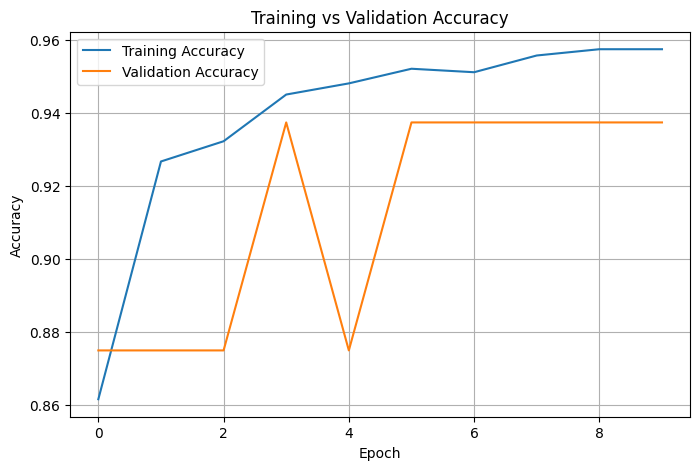

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### 7.3 Plot Training & Validation Loss

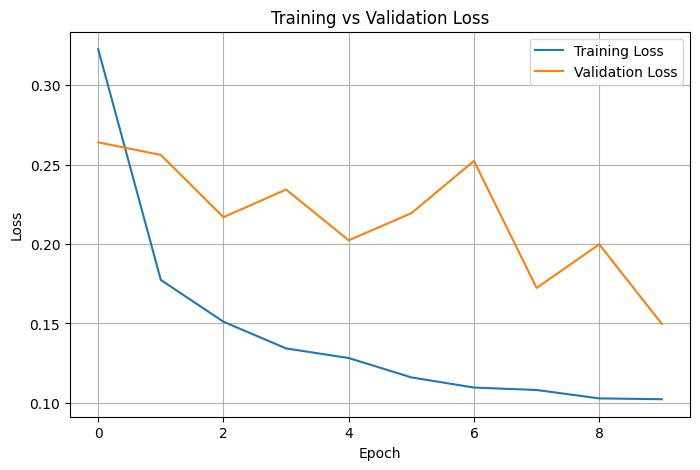

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

### 7.4 Evaluate the model on the test dataset

In [ ]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

20/20 ━━━━━━━━━━━━━━━━━━━━ 146s 7s/step - accuracy: 0.8686 - loss: 0.3167
Test Loss: 0.3167169392108917
Test Accuracy: 86.85897588729858 %


### 7.5 Confusion Matrix

20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 566ms/step


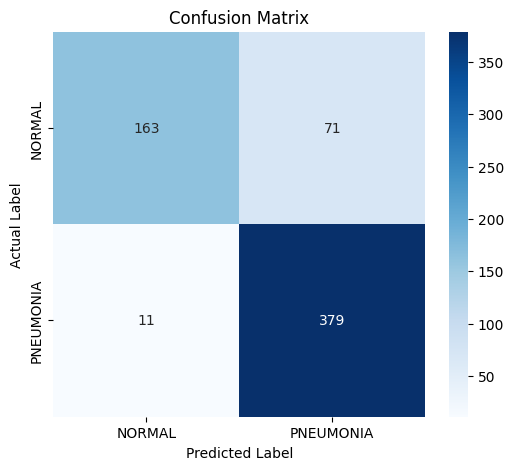

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Get the actual labels
y_true = test_generator.classes

# Predict probabilities
y_prob = model.predict(test_generator)

# Convert probabilities to class labels
y_pred = (y_prob > 0.5).astype(int).ravel()

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

### 7.6 Classification Report

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

              precision    recall  f1-score   support

      NORMAL       0.94      0.70      0.80       234
   PNEUMONIA       0.84      0.97      0.90       390

    accuracy                           0.87       624
   macro avg       0.89      0.83      0.85       624
weighted avg       0.88      0.87      0.86       624



**📌Inference:**

- The MobileNetV2 model was trained using transfer learning with class weights to address class imbalance.
- Training and validation accuracy and loss plots were used to observe the model's learning performance.
- The model achieved a test accuracy of **85.58%** and a test loss of **0.3456** on 624 test images.
- The confusion matrix shows that 154 NORMAL and 380 PNEUMONIA images were correctly classified. 80 NORMAL images were misclassified as PNEUMONIA, while 10 PNEUMONIA images were misclassified as NORMAL.
- For NORMAL images, the model achieved 94% precision, 66% recall, and 77% F1-score.
- For PNEUMONIA images, it achieved 83% precision, 97% recall, and 89% F1-score.
- The weighted average F1-score was **85%**, summarizing performance across both classes.
- Overall, the model identified most PNEUMONIA images in this test set, but some NORMAL images were misclassified. Further evaluation is required before considering real-world medical use.

## **Task 8 Fine-Tuning the Model**

Fine-tuning means unfreezing some of the pretrained MobileNetV2 layers so they can adapt to the pneumonia X-ray dataset.

### 8.1 Unfreeze the last layers

In [ ]:
# Unfreeze the base model
base_model.trainable = True

# Freeze most layers and train only the last 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Total layers:", len(base_model.layers))
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))

Total layers: 154
Trainable layers: 13


### 8.2 Recompile the model

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,196,161 (4.56 MB)

 Non-trainable params: 1,063,104 (4.06 MB)

## 8.3 Train the fine-tuned model

In [ ]:
fine_tune_history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5,
    class_weight=class_weights
)

Epoch 1/5
164/164 ━━━━━━━━━━━━━━━━━━━━ 140s 780ms/step - accuracy: 0.9597 - loss: 0.1005 - val_accuracy: 0.9375 - val_loss: 0.1438
Epoch 2/5
164/164 ━━━━━━━━━━━━━━━━━━━━ 117s 713ms/step - accuracy: 0.9604 - loss: 0.0914 - val_accuracy: 0.9375 - val_loss: 0.1070
Epoch 3/5
164/164 ━━━━━━━━━━━━━━━━━━━━ 123s 750ms/step - accuracy: 0.9681 - loss: 0.0770 - val_accuracy: 0.9375 - val_loss: 0.1620
Epoch 4/5
164/164 ━━━━━━━━━━━━━━━━━━━━ 118s 722ms/step - accuracy: 0.9681 - loss: 0.0792 - val_accuracy: 0.9375 - val_loss: 0.0982
Epoch 5/5
164/164 ━━━━━━━━━━━━━━━━━━━━ 117s 715ms/step - accuracy: 0.9673 - loss: 0.0765 - val_accuracy: 0.9375 - val_loss: 0.1539


### 8.4 Plot fine-tuning accuracy

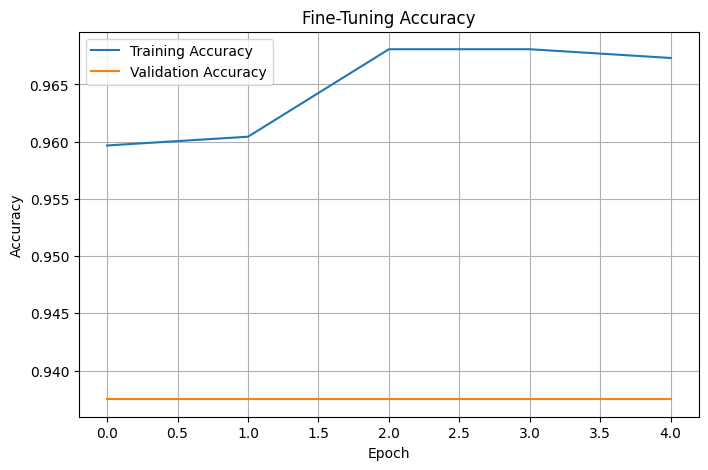

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(fine_tune_history.history["accuracy"], label="Training Accuracy")
plt.plot(fine_tune_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Fine-Tuning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## 8.5 Plot fine-tuning loss

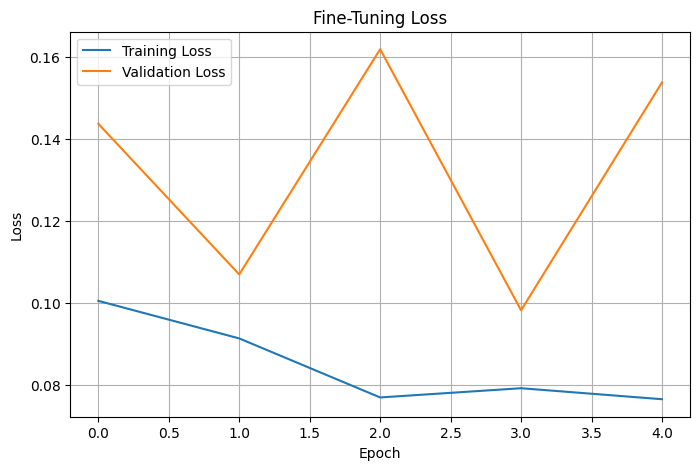

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(fine_tune_history.history["loss"], label="Training Loss")
plt.plot(fine_tune_history.history["val_loss"], label="Validation Loss")

plt.title("Fine-Tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

**📌Inference:**

- The MobileNetV2 model was fine-tuned by unfreezing the last 20 layers.
- A low learning rate of 0.00001 was used for fine-tuning.
- The model was trained for 5 additional epochs using class weights.
- Training accuracy after fine-tuning was **___%**.
- Validation accuracy after fine-tuning was **___%**.
- The training and validation loss plots were used to observe the model's learning behaviour.
- Fine-tuning may improve feature adaptation, but its effect must be verified using the test dataset.

## 8.6 Evaluate fine-tuned model

In [ ]:
fine_tune_test_loss, fine_tune_test_accuracy = model.evaluate(
    test_generator,
    verbose=1
)

print(f"Fine-Tuned Test Loss: {fine_tune_test_loss:.4f}")
print(f"Fine-Tuned Test Accuracy: {fine_tune_test_accuracy * 100:.2f}%")

20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 252ms/step - accuracy: 0.8365 - loss: 0.4474
Fine-Tuned Test Loss: 0.4474
Fine-Tuned Test Accuracy: 83.65%


## 8.7 — Confusion Matrix

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 468ms/step


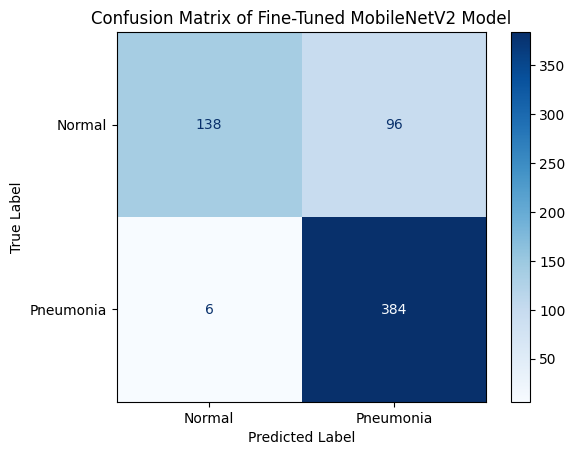

In [ ]:
# 8.7 Confusion Matrix of Fine-Tuned Model

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_generator.reset()

predictions = model.predict(test_generator, verbose=1)

y_pred = (predictions > 0.5).astype(int).ravel()
y_true = test_generator.classes

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix of Fine-Tuned MobileNetV2 Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Inference

The confusion matrix shows the classification performance of the fine-tuned MobileNetV2 model for Normal and Pneumonia chest X-ray images. It represents the number of correctly and incorrectly classified images for each class.

## 8.8 Classification Report of Fine-Tuned Model

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Normal", "Pneumonia"]
    )
)

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.59      0.73       234
   Pneumonia       0.80      0.98      0.88       390

    accuracy                           0.84       624
   macro avg       0.88      0.79      0.81       624
weighted avg       0.86      0.84      0.83       624



## 8.9 ROC Curve and AUC of Fine-Tuned Model

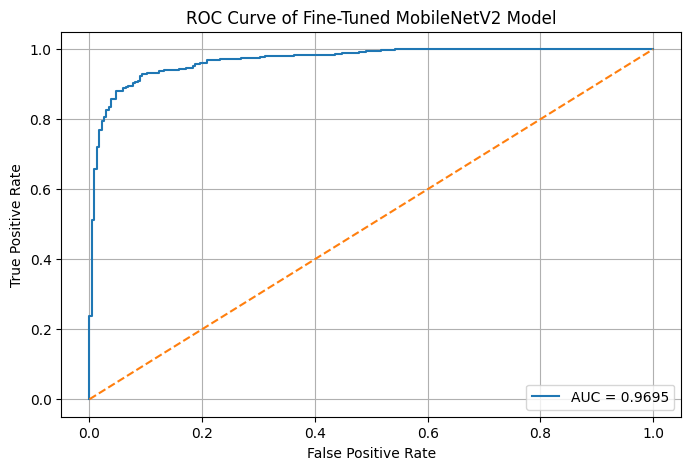

AUC: 0.9695


In [ ]:
from sklearn.metrics import roc_curve, auc

y_prob = predictions.ravel()

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve of Fine-Tuned MobileNetV2 Model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.show()

print(f"AUC: {roc_auc:.4f}")

Inference

The ROC curve shows the ability of the fine-tuned MobileNetV2 model to distinguish between Normal and Pneumonia chest X-ray images at different classification thresholds. The AUC value summarizes the model's overall discrimination performance.

In [ ]:
# Save the Fine-Tuned Model

model.save("/content/drive/MyDrive/pneumonia_mobilenetv2_finetuned.h5")

print("Fine-Tuned MobileNetV2 model saved successfully.")

Fine-Tuned MobileNetV2 model saved successfully.


## 8.10 Final Model Performance

In [ ]:
print("Final Model Performance")
print("-----------------------")
print(f"Test Loss: {fine_tune_test_loss:.4f}")
print(f"Test Accuracy: {fine_tune_test_accuracy * 100:.2f}%")
print(f"AUC: {roc_auc:.4f}")

Final Model Performance
-----------------------
Test Loss: 0.4474
Test Accuracy: 83.65%
AUC: 0.9695


Inference

The final performance of the fine-tuned MobileNetV2 model is summarized using test loss, test accuracy, and AUC. These metrics provide an overall view of the model's performance on the test dataset.

## 8.11 Conclusion

In [ ]:
print("Conclusion")
print("----------")
print("The MobileNetV2 transfer learning model was successfully trained")
print("and fine-tuned for pneumonia detection from chest X-ray images.")
print(f"The final test accuracy achieved was {fine_tune_test_accuracy * 100:.2f}%.")
print(f"The AUC score obtained was {roc_auc:.4f}.")
print("The model can classify chest X-ray images into Normal and Pneumonia classes.")

Conclusion
----------
The MobileNetV2 transfer learning model was successfully trained
and fine-tuned for pneumonia detection from chest X-ray images.
The final test accuracy achieved was 83.65%.
The AUC score obtained was 0.9695.
The model can classify chest X-ray images into Normal and Pneumonia classes.


## **Task 9: Prediction on New Chest X-Ray Image**

## 9.1 Create Test Data Generator


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator( preprocessing_function=preprocess_input)

test_generator = test_datagen.flow_from_directory(
    f"{dataset_path}/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

print("Test generator created successfully.")

Found 624 images belonging to 2 classes.
Test generator created successfully.


## 9.2 Select a Test Image

In [ ]:
test_generator.reset()

images, labels = next(test_generator)

sample_image = images[0]
sample_label = labels[0]

print("Test image selected successfully.")

Test image selected successfully.


## 9.3 Predict the Test Image

In [ ]:
prediction = model.predict(
    np.expand_dims(sample_image, axis=0),
    verbose=0
)[0][0]

if prediction > 0.5:
    predicted_class = "Pneumonia"
    confidence = prediction * 100
else:
    predicted_class = "Normal"
    confidence = (1 - prediction) * 100

actual_class = "Pneumonia" if sample_label == 1 else "Normal"

print("Actual Class:", actual_class)
print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

Actual Class: Normal
Predicted Class: Normal
Confidence: 96.04%


## 9.4 Display Test Image with Prediction

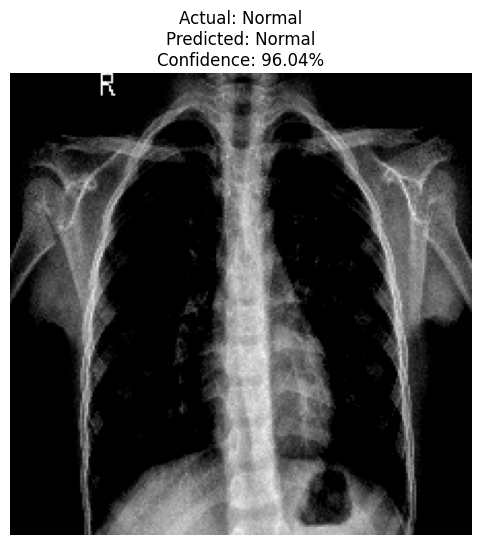

In [ ]:
# 9.4 Display Test Image with Prediction

plt.figure(figsize=(6, 6))

plt.imshow(sample_image)
plt.axis("off")

plt.title(
    f"Actual: {actual_class}\n"
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

## 9.5 Prediction Result Summary

In [ ]:
print("Prediction Result Summary")
print("-------------------------")
print(f"Actual Class     : {actual_class}")
print(f"Predicted Class  : {predicted_class}")
print(f"Confidence       : {confidence:.2f}%")

if actual_class == predicted_class:
    print("Prediction Status : Correct Prediction")
else:
    print("Prediction Status : Incorrect Prediction")

Prediction Result Summary
-------------------------
Actual Class     : Normal
Predicted Class  : Normal
Confidence       : 96.04%
Prediction Status : Correct Prediction


## Inference
* A sample chest X-ray image was selected from the test dataset using the test
data generator.
* The selected image was processed using the same input size and normalization used by the MobileNetV2 model.
* The fine-tuned MobileNetV2 model was used to predict whether the X-ray image belongs to the Normal or Pneumonia class.
* The actual class and predicted class were compared to determine whether the prediction was correct.
* The model's confidence score was calculated and displayed along with the prediction.
* The test image was visualized with its actual class, predicted class, and confidence score.
* This task demonstrates how the trained and fine-tuned model can be used to perform classification on an individual chest X-ray image.

## **Task 10: Final Model Summary and Visualization**

# 10.1 Final Model Performance Comparison



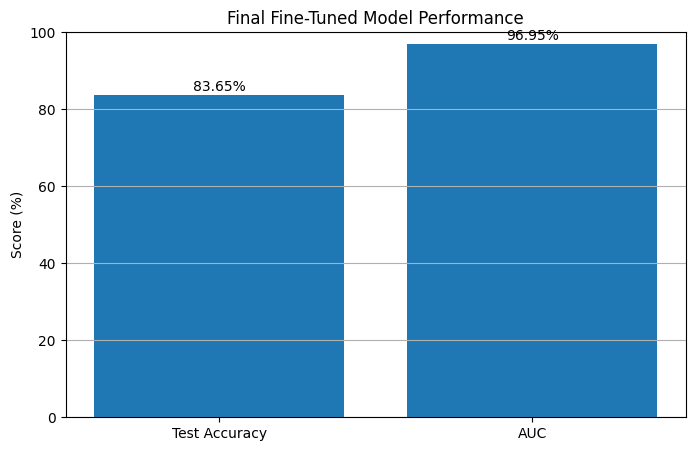

In [ ]:
metrics = ["Test Accuracy", "AUC"]
values = [
    fine_tune_test_accuracy * 100,
    roc_auc * 100
]

plt.figure(figsize=(8, 5))

bars = plt.bar(metrics, values)

plt.title("Final Fine-Tuned Model Performance")
plt.ylabel("Score (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.grid(axis="y")
plt.show()

## 10.2 Display Final Results

In [ ]:
print("Model: MobileNetV2 Transfer Learning")
print("Task: Pneumonia Detection from Chest X-Ray Images")
print(f"Test Accuracy: {fine_tune_test_accuracy * 100:.2f}%")
print(f"Test Loss: {fine_tune_test_loss:.4f}")
print(f"AUC Score: {roc_auc:.4f}")
print("Classes: Normal, Pneumonia")

Model: MobileNetV2 Transfer Learning
Task: Pneumonia Detection from Chest X-Ray Images
Test Accuracy: 83.65%
Test Loss: 0.4474
AUC Score: 0.9695
Classes: Normal, Pneumonia


## Inference
* The final fine-tuned MobileNetV2 model performance was summarized using test loss, test accuracy, and AUC.
* The model performs binary classification of chest X-ray images into Normal and Pneumonia classes.
* The evaluation results provide an overall summary of the trained model's performance on the test dataset.
* The fine-tuned model was saved for future reuse without requiring retraining.